In [1]:
import pandas as pd

df = pd.read_csv("../Level_1/zomato.csv", encoding="latin-1")
print(df.shape)
df.head()

(9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [4]:
# Rating distribution
print(df["Aggregate rating"].describe())

bins = [0, 1, 2, 3, 4, 5]
labels = ["0-1", "1-2", "2-3", "3-4", "4-5"]
df["Rating Range"] = pd.cut(df["Aggregate rating"], bins=bins, labels=labels, include_lowest=True)

rating_dist = df["Rating Range"].value_counts().sort_index()
print("\nRating Range Distribution")
print(rating_dist)

print("\nMost common rating range:", rating_dist.idxmax())
print("Average votes per restaurant:", round(df["Votes"].mean(), 2))

count    9551.000000
mean        2.666370
std         1.516378
min         0.000000
25%         2.500000
50%         3.200000
75%         3.700000
max         4.900000
Name: Aggregate rating, dtype: float64

Rating Range Distribution
Rating Range
0-1    2148
1-2      10
2-3    1891
3-4    4388
4-5    1114
Name: count, dtype: int64

Most common rating range: 3-4
Average votes per restaurant: 156.91


In [2]:
import pandas as pd

df = pd.read_csv(r"C:\Users\ALL AtoZ\Cognifyz_Data_Analytics\Level_1\zomato.csv", encoding="latin-1")
print(df.shape)

(9551, 21)


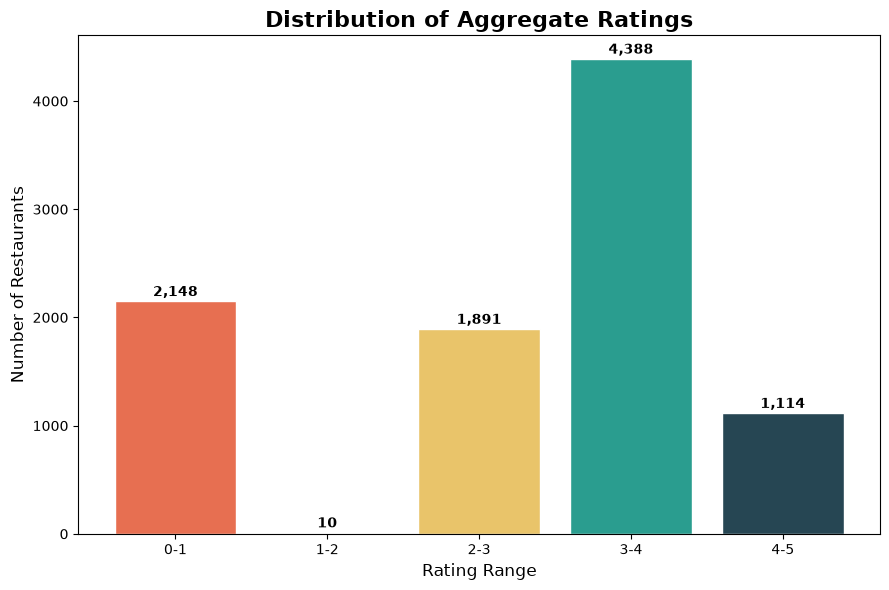

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))
bars = plt.bar(rating_dist.index.astype(str), rating_dist.values,
               color=["#E76F51", "#F4A261", "#E9C46A", "#2A9D8F", "#264653"],
               edgecolor="white")

for bar, count in zip(bars, rating_dist.values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 50,
             f"{count:,}", ha="center", fontweight="bold")

plt.title("Distribution of Aggregate Ratings", fontsize=16, fontweight="bold")
plt.xlabel("Rating Range", fontsize=12)
plt.ylabel("Number of Restaurants", fontsize=12)
plt.tight_layout()
plt.savefig("Rating_Distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### Insights: Restaurant Ratings
- The most common rating range is 3-4, with 4,388 restaurants (45.9%).
- 2,148 restaurants fall in the 0-1 range, mostly unrated restaurants with a rating of 0.
- Only 1,114 restaurants (11.7%) have a rating of 4 or above.
- Restaurants receive 156.91 votes on average.

In [8]:
# Most common cuisine combinations
combo_df = df.dropna(subset=["Cuisines"]).copy()
combo_df["Cuisine Combination"] = combo_df["Cuisines"].apply(
    lambda x: ", ".join(sorted([c.strip() for c in x.split(",")]))
)

top_combos = combo_df["Cuisine Combination"].value_counts().head(10)
print("TOP 10 CUISINE COMBINATIONS")
print(top_combos)

# Average rating for the top combinations
combo_rating = (
    combo_df[combo_df["Cuisine Combination"].isin(top_combos.index)]
    .groupby("Cuisine Combination")["Aggregate rating"]
    .agg(["count", "mean"])
    .round(2)
    .sort_values("mean", ascending=False)
)
print("\nAVERAGE RATING OF TOP COMBINATIONS")
print(combo_rating)

TOP 10 CUISINE COMBINATIONS
Cuisine Combination
North Indian                      936
Chinese, North Indian             616
Mughlai, North Indian             394
Chinese                           354
Fast Food                         354
Chinese, Mughlai, North Indian    306
Cafe                              299
Bakery                            218
Bakery, Desserts                  181
Chinese, Fast Food                159
Name: count, dtype: int64

AVERAGE RATING OF TOP COMBINATIONS
                                count  mean
Cuisine Combination                        
Cafe                              299  2.89
Mughlai, North Indian             394  2.77
Chinese, Mughlai, North Indian    306  2.62
Bakery, Desserts                  181  2.38
Chinese, North Indian             616  2.33
Fast Food                         354  2.12
Chinese, Fast Food                159  2.07
Chinese                           354  2.04
Bakery                            218  1.92
North Indian              

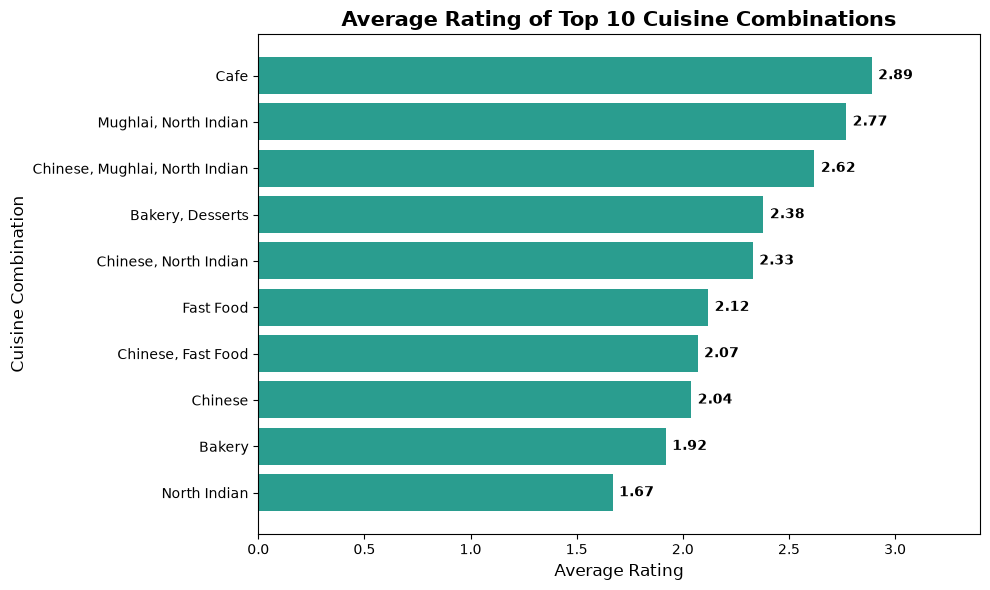

In [9]:
import matplotlib.pyplot as plt

plot_df = combo_rating.sort_values("mean")

plt.figure(figsize=(10, 6))
bars = plt.barh(plot_df.index, plot_df["mean"], color="#2A9D8F")

for bar, val in zip(bars, plot_df["mean"]):
    plt.text(val + 0.03, bar.get_y() + bar.get_height() / 2,
             f"{val:.2f}", va="center", fontweight="bold")

plt.title("Average Rating of Top 10 Cuisine Combinations", fontsize=15, fontweight="bold")
plt.xlabel("Average Rating", fontsize=12)
plt.ylabel("Cuisine Combination", fontsize=12)
plt.xlim(0, 3.4)
plt.tight_layout()
plt.savefig("Cuisine_Combination_Ratings.png", dpi=300, bbox_inches="tight")
plt.show()

### Insights: Cuisine Combinations
- North Indian alone is the most common combination with 936 restaurants, followed by Chinese + North Indian (616) and Mughlai + North Indian (394).
- Among the top 10 combinations, Cafe has the highest average rating (2.89), followed by Mughlai + North Indian (2.77).
- North Indian alone has the lowest average rating (1.67), while adding Mughlai raises it to 2.77.
- Cuisine combinations do show rating differences, but these are averages and not proof of cause.